<a href="https://colab.research.google.com/github/nycolasAugusto/IA-ImpostosSobreIm-veis/blob/main/Grupo_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

✅ Dados lidos da URL pública (GitHub).

Dimensões: 20640 linhas x 13 colunas
Duplicatas (sem ID): 0
Nulos por coluna:
 total_bedrooms    207
Valores censurados no teto : 992
Rendas censuradas no teto  : 51
Idade no teto (52 ou mais) : 1273 (mantidos, tratados como limite inferior)
Categorias de ocean_proximity:
 ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5


,Valor_Imovel_Mil_BRL,Renda_Media_Zona_Mil_BRL,Media_Comodos_Por_Casa,Idade_Mediana_Imoveis,Imposto_IPTU_Anual_BRL,Preco_Renda
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,1034.28,193.53,5.43,28.64,10342.79,5.65
std,576.98,94.99,2.47,12.59,5769.77,3.24
min,75.00,25.00,0.85,1.00,750.00,0.36
25%,598.00,128.17,4.44,18.00,5980.00,3.86
50%,898.50,176.74,5.23,29.00,8985.00,4.95
75%,1323.62,237.16,6.05,37.00,13236.25,6.59
max,2500.00,750.00,141.91,52.00,25000.00,100.00


,Etapa,Linhas,Removidas
0,Base bruta,20640,0
1,Sem duplicatas,20640,0
2,Sem NaN/erros de domínio,20640,0
3,Sem valores/rendas censurados no teto,19645,995
4,Sem outliers de cômodos (IQR x3),19465,180


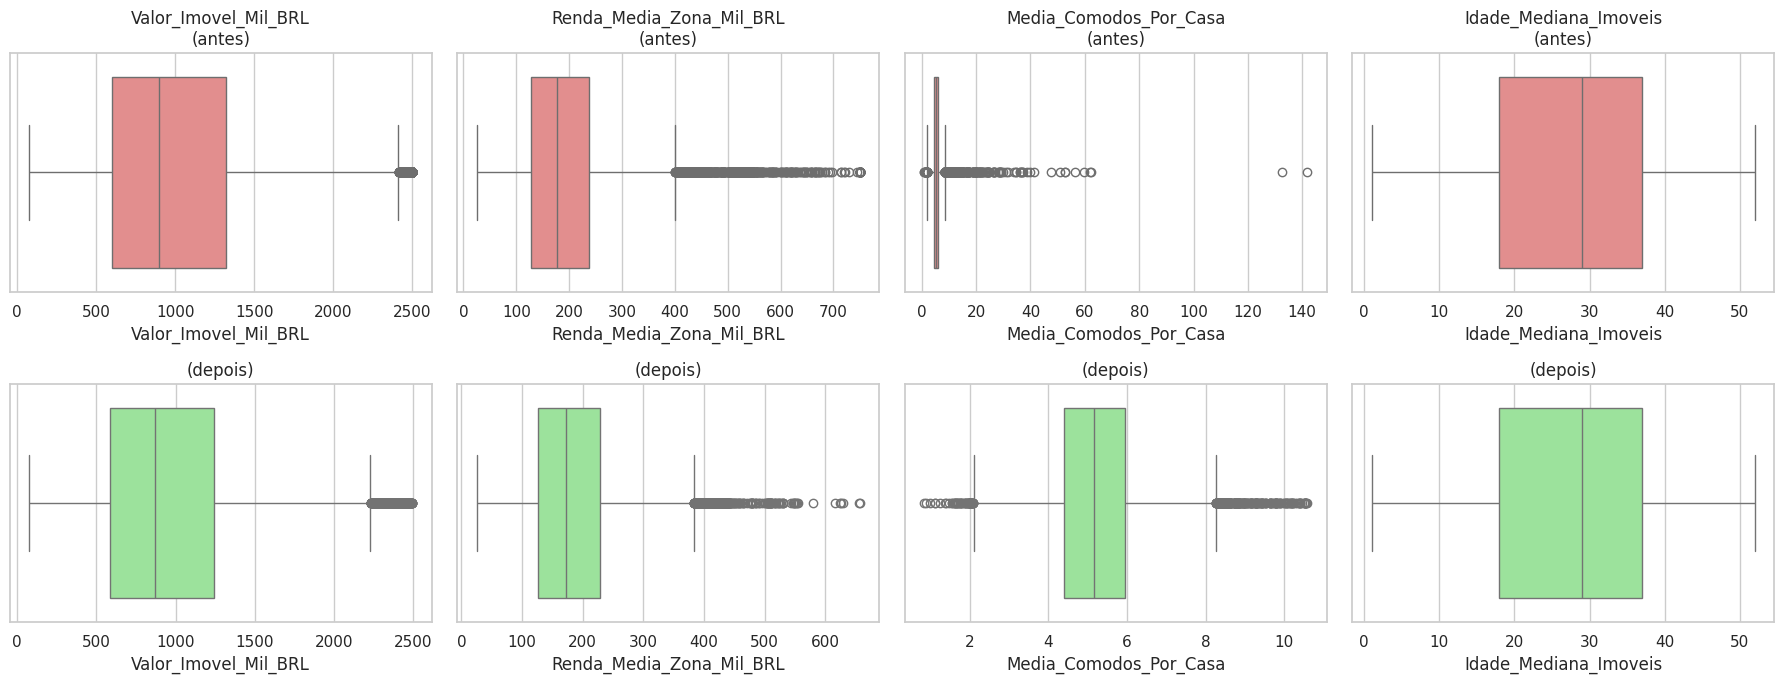

,Variável vs Valor do Imóvel,r (Pearson),p-valor
0,Renda_Media_Zona_Mil_BRL,0.649,0.0e+00
1,Media_Comodos_Por_Casa,0.252,9.0e-280
2,Idade_Mediana_Imoveis,0.065,1.2e-19



✅ Base limpa: 19465 linhas (94.3% da bruta).


In [ ]:
# ==============================================================================
# PASSOS 1 E 2 — DIAGNÓSTICO E WRANGLING (AULA 09)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

pd.set_option('display.max_columns', 30); pd.set_option('display.width', 1000)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.figsize'] = (12, 5)

# ------------------------------ 0. PARÂMETROS --------------------------------
SEED, COTACAO = 42, 5.0                        # semente e cotação USD->BRL (fixa)
ALIQUOTA_IPTU = 0.01                           # alíquota fixa (~1%):
URL = 'https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv'
LIM_VALOR = 500000 * COTACAO / 1000            # teto de censura do valor (Censo)
LIM_RENDA = 15 * 10 * COTACAO                  # teto de censura da renda (Censo)
COL_NUM = ['Valor_Imovel_Mil_BRL', 'Renda_Media_Zona_Mil_BRL', 'Media_Comodos_Por_Casa',
           'Idade_Mediana_Imoveis', 'Imposto_IPTU_Anual_BRL', 'Preco_Renda']

# ------------------------------ LEITURA (Colab) ------------------------------
try:
    df_raw = pd.read_csv(URL);  print("✅ Dados lidos da URL pública (GitHub).")
except Exception:
    try:
        df_raw = pd.read_csv('housing.csv');  print("✅ Dados lidos do arquivo local.")
    except Exception:
        from google.colab import files
        print("📂 Faça o upload do housing.csv:")
        df_raw = pd.read_csv(next(iter(files.upload())))

# ------------------------------ COLUNAS DO PROJETO (em R$) -------------------
df = pd.DataFrame({
    'ID_Zona': [f'Z_{i+1:05d}' for i in range(len(df_raw))],
    'Valor_Imovel_Mil_BRL': (df_raw['median_house_value'] * COTACAO / 1000).round(2),
    'Renda_Media_Zona_Mil_BRL': (df_raw['median_income'] * 10 * COTACAO).round(2),
    'Media_Comodos_Por_Casa': (df_raw['total_rooms'] / df_raw['households'].replace(0, np.nan)).round(3),
    'Idade_Mediana_Imoveis': df_raw['housing_median_age'],
})
df['Imposto_IPTU_Anual_BRL'] = (df['Valor_Imovel_Mil_BRL'] * 1000 * ALIQUOTA_IPTU).round(2)
df['Preco_Renda'] = (df['Valor_Imovel_Mil_BRL'] / df['Renda_Media_Zona_Mil_BRL']).round(3)   # anos de renda p/ comprar
for c in ['total_bedrooms', 'population', 'households', 'ocean_proximity', 'latitude', 'longitude']:
    df[c] = df_raw[c].values

# ==============================================================================
# PASSO 1 — DIAGNÓSTICO (duplicatas, nulos, categorias, anomalias)
# ==============================================================================
print(f"\nDimensões: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("Duplicatas (sem ID):", df.drop(columns='ID_Zona').duplicated().sum())
nulos = df.isnull().sum();  print("Nulos por coluna:\n", nulos[nulos > 0].to_string())
print("Valores censurados no teto :", (df['Valor_Imovel_Mil_BRL'] >= LIM_VALOR).sum())
print("Rendas censuradas no teto  :", (df['Renda_Media_Zona_Mil_BRL'] >= LIM_RENDA).sum())
print("Idade no teto (52 ou mais) :", (df['Idade_Mediana_Imoveis'] >= 52).sum(), "(mantidos, tratados como limite inferior)")
print("Categorias de ocean_proximity:\n", df['ocean_proximity'].value_counts().to_string())
display(df[COL_NUM].describe().round(2))

# ==============================================================================
# PASSO 2 — LIMPEZA E FILTRAGEM DE OUTLIERS
# ==============================================================================
def mask_iqr(s, k=3.0):
    q1, q3 = s.quantile(0.25), s.quantile(0.75);  i = q3 - q1
    return (s >= q1 - k * i) & (s <= q3 + k * i)

log = [('Base bruta', len(df))]

df_limpo = df.loc[~df.drop(columns='ID_Zona').duplicated(keep='first')].copy()          # 1) duplicatas
log.append(('Sem duplicatas', len(df_limpo)))

df_limpo['ocean_proximity'] = df_limpo['ocean_proximity'].str.strip().str.title()       # 2) padroniza texto

for c in COL_NUM:                                                                       # 3) erro de domínio -> NaN
    df_limpo.loc[df_limpo[c] <= 0, c] = np.nan
df_limpo = df_limpo.dropna(subset=COL_NUM)
log.append(('Sem NaN/erros de domínio', len(df_limpo)))

df_limpo = df_limpo[(df_limpo['Valor_Imovel_Mil_BRL'] < LIM_VALOR) &                    # 4) valores censurados
                    (df_limpo['Renda_Media_Zona_Mil_BRL'] < LIM_RENDA)]
log.append(('Sem valores/rendas censurados no teto', len(df_limpo)))

df_limpo = df_limpo[mask_iqr(df_limpo['Media_Comodos_Por_Casa'])].reset_index(drop=True) # 5) outliers de cômodos
log.append(('Sem outliers de cômodos (IQR x3)', len(df_limpo)))
# total_bedrooms mantém NaN de propósito: será imputado só com a mediana do TREINO (Passo 3)

tab = pd.DataFrame(log, columns=['Etapa', 'Linhas'])
tab['Removidas'] = (-tab['Linhas'].diff()).fillna(0).astype(int)
display(tab)

# ------------------------------ Conferência: antes x depois ------------------
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, c in enumerate(['Valor_Imovel_Mil_BRL', 'Renda_Media_Zona_Mil_BRL', 'Media_Comodos_Por_Casa', 'Idade_Mediana_Imoveis']):
    sns.boxplot(x=df[c], ax=axes[0, j], color='lightcoral');   axes[0, j].set_title(f'{c}\n(antes)')
    sns.boxplot(x=df_limpo[c], ax=axes[1, j], color='lightgreen'); axes[1, j].set_title('(depois)')
plt.tight_layout(); plt.show()

# ------------------------------ Relação de cada variável com o valor ---------
linhas = []
for c in ['Renda_Media_Zona_Mil_BRL', 'Media_Comodos_Por_Casa', 'Idade_Mediana_Imoveis']:
    r, p = stats.pearsonr(df_limpo[c], df_limpo['Valor_Imovel_Mil_BRL'])
    linhas.append({'Variável vs Valor do Imóvel': c, 'r (Pearson)': round(r, 3), 'p-valor': f'{p:.1e}'})
display(pd.DataFrame(linhas))
print(f"\n✅ Base limpa: {len(df_limpo)} linhas ({len(df_limpo)/len(df)*100:.1f}% da bruta).")

In [ ]:
# ==============================================================================
# PASSO 3 — ENCODING, SPLIT E IMPUTAÇÃO
# ==============================================================================
ALVO = 'Valor_Imovel_Mil_BRL'
# Lista EXPLÍCITA de preditores. Ficam de fora: ID, IPTU e Preco_Renda (calculados a partir do alvo)
# e qualquer coluna criada depois em outras células.
FEATURES_NUM = ['Renda_Media_Zona_Mil_BRL', 'Media_Comodos_Por_Casa', 'Idade_Mediana_Imoveis',
                'total_bedrooms', 'population', 'households']

# 1) One-Hot Encoding da categoria (drop_first evita colinearidade perfeita)
dummies = pd.get_dummies(df_limpo['ocean_proximity'], prefix='ocean_proximity', drop_first=True, dtype=int)
X = pd.concat([df_limpo[FEATURES_NUM], dummies], axis=1)
y = df_limpo[ALVO]
print("Categorias de ocean_proximity:", sorted(df_limpo['ocean_proximity'].unique()))
print("Colunas dummy criadas:", list(dummies.columns))

# 2) Divisão treino/teste (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"\nTreino: {len(X_train)} zonas | Teste: {len(X_test)} zonas")

# 3) Imputação: mediana calculada APENAS no treino, aplicada em treino e teste
print("\nNaN antes da imputação (treino | teste):", int(X_train.isnull().sum().sum()), "|", int(X_test.isnull().sum().sum()))
med_treino = X_train.median()
print("Medianas aprendidas no treino (colunas com NaN):")
display(med_treino[X_train.columns[X_train.isnull().any()]].to_frame('Mediana_Treino'))
X_train, X_test = X_train.fillna(med_treino), X_test.fillna(med_treino)
print("NaN depois da imputação (treino | teste):", int(X_train.isnull().sum().sum()), "|", int(X_test.isnull().sum().sum()))
display(X_train.head())

Categorias de ocean_proximity: ['<1H Ocean', 'Inland', 'Island', 'Near Bay', 'Near Ocean']
Colunas dummy criadas: ['ocean_proximity_Inland', 'ocean_proximity_Island', 'ocean_proximity_Near Bay', 'ocean_proximity_Near Ocean']

Treino: 15572 zonas | Teste: 3893 zonas

NaN antes da imputação (treino | teste): 160 | 40
Medianas aprendidas no treino (colunas com NaN):


,Mediana_Treino
total_bedrooms,436.0


NaN depois da imputação (treino | teste): 0 | 0


,Renda_Media_Zona_Mil_BRL,Media_Comodos_Por_Casa,Idade_Mediana_Imoveis,total_bedrooms,population,households,ocean_proximity_Inland,ocean_proximity_Island,ocean_proximity_Near Bay,ocean_proximity_Near Ocean
17284,228.08,4.337,8.0,1058.0,2595.0,1027.0,0,0,0,0
13415,128.41,5.440,36.0,475.0,1268.0,450.0,0,0,0,1
7047,93.30,3.477,38.0,346.0,1217.0,354.0,0,0,0,0
13945,267.21,7.005,21.0,618.0,1620.0,600.0,0,0,0,0
13586,53.06,2.554,15.0,702.0,914.0,672.0,0,0,0,1


Regressão SIMPLES : Valor = 222.89 + (4.032 x Renda)


,MAE (R$ mil),RMSE (R$ mil),R²
Simples (só Renda),282.893,366.683,0.429
Múltipla (todas),227.159,305.910,0.602


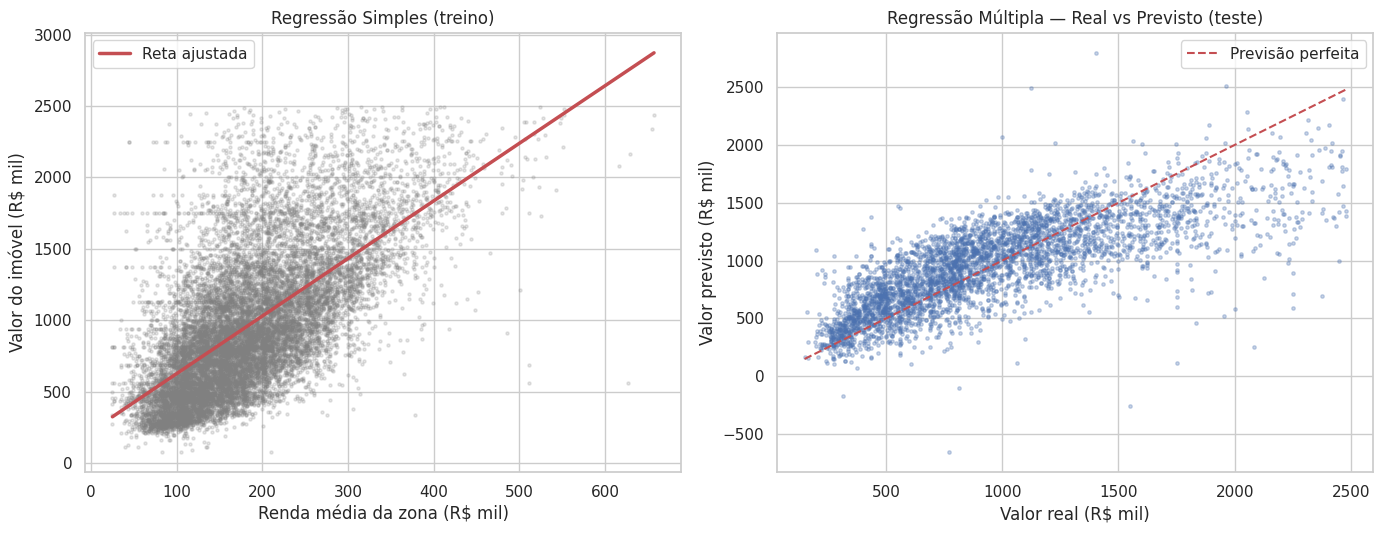

,Variável,Beta (peso)
0,Renda_Media_Zona_Mil_BRL,4.0714
1,Media_Comodos_Por_Casa,-30.7185
2,Idade_Mediana_Imoveis,4.9764
3,total_bedrooms,0.2070
4,population,-0.1619
5,households,0.3314
6,ocean_proximity_Inland,-309.5055
7,ocean_proximity_Island,954.8926
8,ocean_proximity_Near Bay,8.7424
9,ocean_proximity_Near Ocean,67.4895


Intercepto: R$ 280.79 mil

📌 Leitura dos pesos (ceteris paribus, mantendo as demais variáveis constantes):
👉 +R$ 1 mil de renda média da zona        → valor previsto muda R$ 4.07 mil.
👉 +1 ano de idade mediana das construções  → valor previsto muda R$ 4.98 mil.
👉 +1 cômodo por casa                      → valor previsto muda R$ -30.72 mil (cuidado: colinearidade).
👉 Zona no INTERIOR (vs <1h do oceano)      → valor previsto muda R$ -309.51 mil.
👉 Zona NEAR OCEAN (vs <1h do oceano)       → valor previsto muda R$ 67.49 mil.

💎 10 zonas com maior desvio NEGATIVO (preço real bem abaixo do preço justo previsto):


,ID_Zona,ocean_proximity,Idade_Mediana_Imoveis,Media_Comodos_Por_Casa,Imposto_IPTU_Anual_BRL,Valor_Imovel_Mil_BRL,Valor_Previsto_Mil_BRL,Desvio_Pct
0,Z_09189,Inland,52.0,3.57,750.0,75.0,1012.63,-92.59
1,Z_05888,<1H Ocean,39.0,3.57,875.0,87.5,866.35,-89.90
2,Z_01826,Near Bay,33.0,4.70,1125.0,112.5,1079.18,-89.58
3,Z_14327,Near Ocean,52.0,2.25,1125.0,112.5,821.11,-86.30
4,Z_01792,Near Bay,45.0,4.21,1895.0,189.5,1083.12,-82.50
5,Z_04549,<1H Ocean,52.0,3.14,3375.0,337.5,1904.10,-82.28
6,Z_02800,Inland,19.0,3.77,750.0,75.0,415.99,-81.97
7,Z_18212,Near Bay,22.0,4.51,2000.0,200.0,1078.82,-81.46
8,Z_00062,Near Bay,49.0,5.87,3750.0,375.0,1826.25,-79.47
9,Z_15785,Near Bay,52.0,2.65,1625.0,162.5,778.08,-79.12


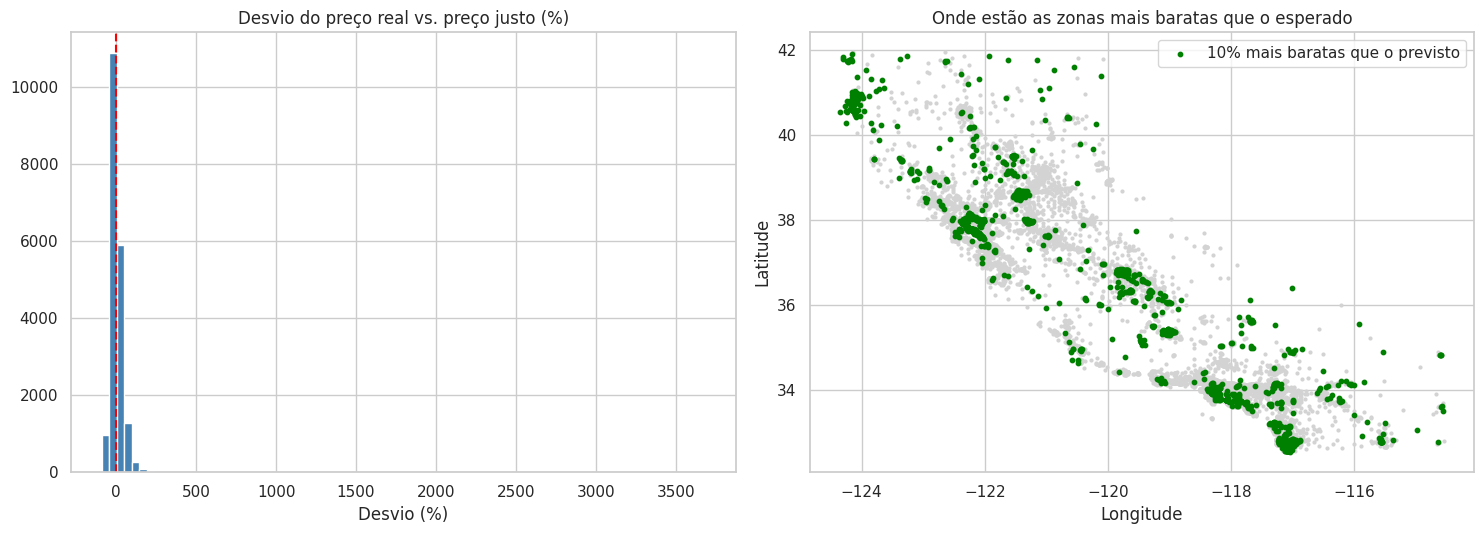

In [ ]:
# ==============================================================================
# PASSOS 4 E 5 — REGRESSÃO E MÉTRICAS (AULA 10)
# ==============================================================================
# ------------------------------ PASSO 4: SIMPLES x MÚLTIPLA ------------------
def avalia(modelo, Xtr, Xte):
    modelo.fit(Xtr, y_train);  p = modelo.predict(Xte)
    return ({'MAE (R$ mil)': mean_absolute_error(y_test, p),
             'RMSE (R$ mil)': np.sqrt(mean_squared_error(y_test, p)),
             'R²': r2_score(y_test, p)}, p)

reg_s, reg_m = LinearRegression(), LinearRegression()
met_s, pred_s = avalia(reg_s, X_train[['Renda_Media_Zona_Mil_BRL']], X_test[['Renda_Media_Zona_Mil_BRL']])
met_m, pred_m = avalia(reg_m, X_train, X_test)

print(f"Regressão SIMPLES : Valor = {reg_s.intercept_:.2f} + ({reg_s.coef_[0]:.3f} x Renda)")
display(pd.DataFrame({'Simples (só Renda)': met_s, 'Múltipla (todas)': met_m}).T.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].scatter(X_train['Renda_Media_Zona_Mil_BRL'], y_train, s=5, alpha=0.2, color='gray')
xs = np.linspace(X_train['Renda_Media_Zona_Mil_BRL'].min(), X_train['Renda_Media_Zona_Mil_BRL'].max(), 100)
ax[0].plot(xs, reg_s.intercept_ + reg_s.coef_[0] * xs, 'r-', lw=2.5, label='Reta ajustada')
ax[0].set_xlabel('Renda média da zona (R$ mil)'); ax[0].set_ylabel('Valor do imóvel (R$ mil)')
ax[0].set_title('Regressão Simples (treino)'); ax[0].legend()
ax[1].scatter(y_test, pred_m, s=6, alpha=0.3)
lim = [y_test.min(), y_test.max()];  ax[1].plot(lim, lim, 'r--', label='Previsão perfeita')
ax[1].set_xlabel('Valor real (R$ mil)'); ax[1].set_ylabel('Valor previsto (R$ mil)')
ax[1].set_title('Regressão Múltipla — Real vs Previsto (teste)'); ax[1].legend()
plt.tight_layout(); plt.show()

# ------------------------------ PASSO 5: INTERPRETAÇÃO DE NEGÓCIO ------------
display(pd.DataFrame({'Variável': X.columns, 'Beta (peso)': reg_m.coef_.round(4)}))
print(f"Intercepto: R$ {reg_m.intercept_:,.2f} mil")
b = dict(zip(X.columns, reg_m.coef_))
print("\n📌 Leitura dos pesos (ceteris paribus, mantendo as demais variáveis constantes):")
print(f"👉 +R$ 1 mil de renda média da zona        → valor previsto muda R$ {b['Renda_Media_Zona_Mil_BRL']:.2f} mil.")
print(f"👉 +1 ano de idade mediana das construções  → valor previsto muda R$ {b['Idade_Mediana_Imoveis']:.2f} mil.")
print(f"👉 +1 cômodo por casa                      → valor previsto muda R$ {b['Media_Comodos_Por_Casa']:.2f} mil (cuidado: colinearidade).")
print(f"👉 Zona no INTERIOR (vs <1h do oceano)      → valor previsto muda R$ {b.get('ocean_proximity_Inland', float('nan')):.2f} mil.")
print(f"👉 Zona NEAR OCEAN (vs <1h do oceano)       → valor previsto muda R$ {b.get('ocean_proximity_Near Ocean', float('nan')):.2f} mil.")

# ------------------------------ PREÇO JUSTO E ZONAS MAIS BARATAS QUE O ESPERADO
# Previsão de TODAS as zonas fora da amostra (validação cruzada 5 folds; imputação dentro de cada fold).
pipe = make_pipeline(SimpleImputer(strategy='median'), LinearRegression())
df_reg = df_limpo.copy()
df_reg['Valor_Previsto_Mil_BRL'] = cross_val_predict(pipe, X, y, cv=5)
df_reg['Desvio_Pct'] = ((df_reg[ALVO] - df_reg['Valor_Previsto_Mil_BRL'])
                        / df_reg['Valor_Previsto_Mil_BRL'].clip(lower=100) * 100)       # negativo = mais barata que o esperado

print("\n 10 zonas com maior desvio NEGATIVO (preço real bem abaixo do preço justo previsto):")
display(df_reg.nsmallest(10, 'Desvio_Pct')[['ID_Zona', 'ocean_proximity', 'Idade_Mediana_Imoveis', 'Media_Comodos_Por_Casa',
        'Imposto_IPTU_Anual_BRL', 'Valor_Imovel_Mil_BRL', 'Valor_Previsto_Mil_BRL', 'Desvio_Pct']].round(2).reset_index(drop=True))

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].hist(df_reg['Desvio_Pct'], bins=80, color='steelblue'); ax[0].axvline(0, color='red', ls='--')
ax[0].set_title('Desvio do preço real vs. preço justo (%)'); ax[0].set_xlabel('Desvio (%)')
bar = df_reg.nsmallest(int(len(df_reg) * 0.10), 'Desvio_Pct')
ax[1].scatter(df_reg['longitude'], df_reg['latitude'], s=4, color='lightgray')
ax[1].scatter(bar['longitude'], bar['latitude'], s=10, color='green', label='10% mais baratas que o previsto')
ax[1].set_title('Onde estão as zonas mais baratas que o esperado'); ax[1].set_xlabel('Longitude'); ax[1].set_ylabel('Latitude'); ax[1].legend()
plt.tight_layout(); plt.show()

Peso de cada variável na distância euclidiana SEM padronizar (% da variância total):


,% da variância
Valor_Imovel_Mil_BRL,97.411
Renda_Media_Zona_Mil_BRL,2.524
Media_Comodos_Por_Casa,0.001
Idade_Mediana_Imoveis,0.064


Após o StandardScaler (média ≈ 0 e desvio-padrão ≈ 1):


,Valor_Imovel_Mil_BRL,Renda_Media_Zona_Mil_BRL,Media_Comodos_Por_Casa,Idade_Mediana_Imoveis
mean,0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0


,K,Inércia,Silhueta
0,2,51443.8,0.3176
1,3,41296.5,0.2543
2,4,34778.1,0.2539
3,5,30857.4,0.2295
4,6,28099.5,0.2262
5,7,25555.2,0.2324
6,8,23950.5,0.2312


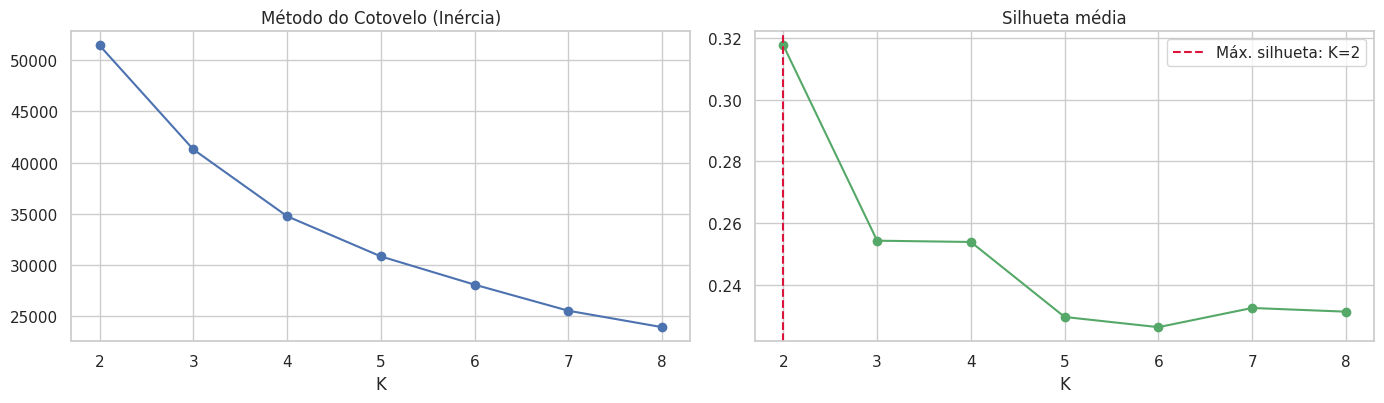

K final = 2
📋 TABELA EXECUTIVA DE PERFIS (do menor para o maior valor médio):


,Qtde,Valor_Mil_BRL,Renda_Mil_BRL,Comodos,Idade_Anos,Preco_Renda,IPTU_BRL,Persona
Cluster,,,,,,,,
0,12684,745.15,140.55,4.69,30.30,5.62,7451.47,Valor médio | Renda baixa | Imóveis intermediá...
1,6781,1366.80,264.55,6.21,25.06,5.34,13667.98,Valor alto | Renda alta | Imóveis intermediári...


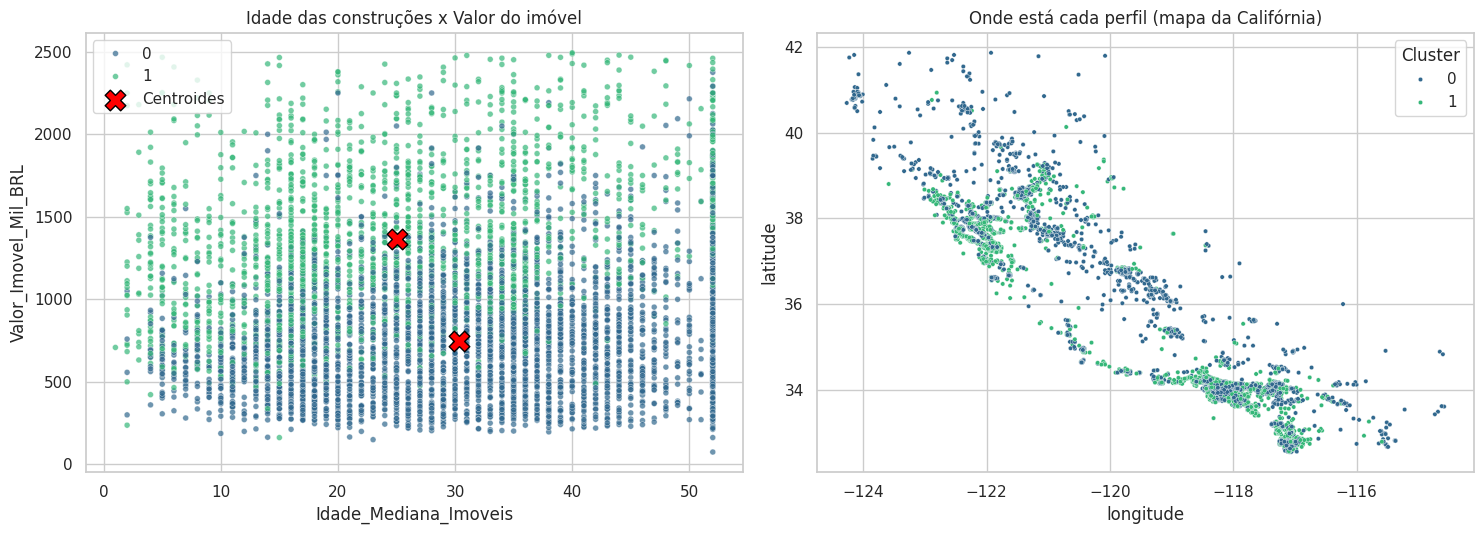

In [ ]:
# ==============================================================================
# ETAPAS 1, 2 E 3 — STANDARDSCALER, COTOVELO/SILHUETA E K-MEANS FINAL (AULA 11)
# ==============================================================================
# IPTU fica de fora: com alíquota fixa ele é 1% do valor (mesma informação, contada duas vezes na distância).
COL_CLUSTER = ['Valor_Imovel_Mil_BRL', 'Renda_Media_Zona_Mil_BRL', 'Media_Comodos_Por_Casa', 'Idade_Mediana_Imoveis']
df_cluster = df_limpo.copy()           # cópia: não altera o df_limpo usado nas outras células

# ------------------------------ ETAPA 1: PADRONIZAÇÃO Z-SCORE ----------------
var = df_cluster[COL_CLUSTER].var()
print("Peso de cada variável na distância euclidiana SEM padronizar (% da variância total):")
display((var / var.sum() * 100).round(3).to_frame('% da variância'))

scaler = StandardScaler().fit(df_cluster[COL_CLUSTER])
X_pad = scaler.transform(df_cluster[COL_CLUSTER])
print("Após o StandardScaler (média ≈ 0 e desvio-padrão ≈ 1):")
display(pd.DataFrame(X_pad, columns=COL_CLUSTER).agg(['mean', 'std']).round(3))

# ------------------------------ ETAPA 2: COTOVELO + SILHUETA -----------------
ks, inercia, silh = list(range(2, 9)), [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X_pad)
    inercia.append(km.inertia_)
    silh.append(silhouette_score(X_pad, km.labels_, sample_size=5000, random_state=SEED))   # amostra: custo computacional
display(pd.DataFrame({'K': ks, 'Inércia': np.round(inercia, 1), 'Silhueta': np.round(silh, 4)}))
K_SUGERIDO = ks[int(np.argmax(silh))]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(ks, inercia, 'bo-');  ax[0].set_title('Método do Cotovelo (Inércia)');  ax[0].set_xlabel('K')
ax[1].plot(ks, silh, 'go-');  ax[1].axvline(K_SUGERIDO, color='crimson', ls='--', label=f'Máx. silhueta: K={K_SUGERIDO}')
ax[1].set_title('Silhueta média');  ax[1].set_xlabel('K');  ax[1].legend()
plt.tight_layout();  plt.show()

# ------------------------------ ETAPA 3: K-MEANS FINAL + PERSONAS ------------
K_ESCOLHIDO = None                    # None = usa o K de maior silhueta | ou force, ex.: 4 (e justifique)
K = K_ESCOLHIDO or K_SUGERIDO
kmeans = KMeans(n_clusters=K, random_state=SEED, n_init=10).fit(X_pad)
df_cluster['Cluster'] = kmeans.labels_
print(f"K final = {K}")

# Rótulo automático comparando cada cluster com a média geral (EDITE conforme a leitura do grupo)
glob_m, glob_s = df_cluster[COL_CLUSTER].mean(), df_cluster[COL_CLUSTER].std()
def rotulo(medias):
    z = (medias - glob_m) / glob_s
    f = lambda v, alto, medio, baixo: alto if v > 0.5 else (baixo if v < -0.5 else medio)
    return (f"Valor {f(z['Valor_Imovel_Mil_BRL'], 'alto', 'médio', 'baixo')} | "
            f"Renda {f(z['Renda_Media_Zona_Mil_BRL'], 'alta', 'média', 'baixa')} | "
            f"Imóveis {f(z['Idade_Mediana_Imoveis'], 'antigos', 'intermediários', 'novos')} | "
            f"Cômodos {f(z['Media_Comodos_Por_Casa'], 'muitos', 'médios', 'poucos')}")

medias = df_cluster.groupby('Cluster')[COL_CLUSTER].mean()
perfil = df_cluster.groupby('Cluster').agg(
    Qtde=('Cluster', 'count'),
    Valor_Mil_BRL=('Valor_Imovel_Mil_BRL', 'mean'),
    Renda_Mil_BRL=('Renda_Media_Zona_Mil_BRL', 'mean'),
    Comodos=('Media_Comodos_Por_Casa', 'mean'),
    Idade_Anos=('Idade_Mediana_Imoveis', 'mean'),
    Preco_Renda=('Preco_Renda', 'mean'),
    IPTU_BRL=('Imposto_IPTU_Anual_BRL', 'mean')).round(2)
perfil['Persona'] = [rotulo(medias.loc[c]) for c in perfil.index]
perfil = perfil.sort_values('Valor_Mil_BRL')
print("📋 TABELA EXECUTIVA DE PERFIS (do menor para o maior valor médio):")
display(perfil)
df_cluster['Persona'] = df_cluster['Cluster'].map(perfil['Persona'])

# Visualizações
amostra = df_cluster.sample(min(6000, len(df_cluster)), random_state=SEED)
cen = scaler.inverse_transform(kmeans.cluster_centers_)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=amostra, x='Idade_Mediana_Imoveis', y='Valor_Imovel_Mil_BRL', hue='Cluster', palette='viridis', s=18, alpha=0.7, ax=ax[0])
ax[0].scatter(cen[:, COL_CLUSTER.index('Idade_Mediana_Imoveis')], cen[:, COL_CLUSTER.index('Valor_Imovel_Mil_BRL')],
              c='red', marker='X', s=220, edgecolor='black', label='Centroides')
ax[0].set_title('Idade das construções x Valor do imóvel');  ax[0].legend()
sns.scatterplot(data=amostra, x='longitude', y='latitude', hue='Cluster', palette='viridis', s=10, ax=ax[1])
ax[1].set_title('Onde está cada perfil (mapa da Califórnia)')
plt.tight_layout();  plt.show()